# A finite-element solve that stops when it has converged

> Assemble the load once, then solve in one graph. The loop checks its own residual on the device and leaves as soon as it
> is small, so you never pick an iteration count.

**Time:** ~8 min · **Runs on:** CPU (a GPU is picked up automatically and runs a finer mesh) · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`../graph_across_devices`

The problem is Poisson's equation on the unit square, `-laplacian(u) = f` with `u = 0` on the edge and
`f = 2 pi^2 sin(pi x) sin(pi y)`, whose exact solution is `sin(pi x) sin(pi y)`. A triangle mesh turns it into a linear
system `K u = b`. The assembly of the load `b` is [hawk's finite-element page](https://amasat01.github.io/hawk/content/vocabulary/07_fem_assembly.html):
one lane per (triangle, corner) and `hawk.scatter` into the nodes. Here the same pattern also applies the stiffness matrix
`K` to a vector without ever storing it, and eagle composes that into a solver: Jacobi-preconditioned conjugate
gradients (PCG), with Jacobi iteration beside it for comparison.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import gpu_available, plot_style, to_numpy, xp_for

In [3]:
import numpy as np

DEVICE = "gpu" if gpu_available() else "cpu"
xp = xp_for(DEVICE)
SIDE = 32 if DEVICE == "gpu" else 8                # squares per side
print("running on", DEVICE, f"with {SIDE} x {SIDE} squares")

running on cpu with 8 x 8 squares


## The mesh

The unit square cut into triangles, with the inner nodes nudged so it is not a regular grid (the same mesh as in hawk's
page). `conn` lists the three node numbers of each triangle.

In [4]:
def make_mesh(side):
    xs, ys = np.meshgrid(np.linspace(0, 1, side + 1), np.linspace(0, 1, side + 1))
    nodes = np.c_[xs.ravel(), ys.ravel()]
    rng = np.random.default_rng(7)
    inner = ((nodes > 0) & (nodes < 1)).all(axis=1)
    nodes[inner] += rng.uniform(-0.15, 0.15, size=(inner.sum(), 2)) / side
    tri = []
    for j in range(side):
        for i in range(side):
            a = j * (side + 1) + i
            b, c, d = a + 1, a + side + 1, a + side + 2
            tri += [[a, b, d], [a, d, c]]
    return nodes, np.array(tri, dtype=np.int32), inner

## The mesh kernels

Three kernels share one lane layout, `Grid["e", "a":3]`: a lane per corner `a` of triangle `e`.

- `load` is hawk's assembly: each corner gets a third of `f * area`, scattered into its node.
- `diagonal` assembles the diagonal of `K`, which the preconditioner divides by.
- `stiffness` applies `K` to a vector `u`. For a triangle with corner coordinates, `K` has the local entries
  `(b_i b_j + c_i c_j) / (4 area)` with `b_i`, `c_i` the differences of the other two corners' coordinates. A lane takes
  its own row of that local matrix times the three corner values of `u` and scatters it into its node.

`stiffness` scatters with `policy="plain"`. A compensated scatter keeps a hidden companion that persists between launches and
is folded into the target after each launch, so a sink cleared every iteration would carry a stale residual; and the solver's
tolerance dominates the rounding of this product anyway.

In [5]:
import functools
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Index, Mutable, Param, Scalar, Table, UInt32

PI = 3.141592653589793


@functools.lru_cache(maxsize=None)
def mesh_kernels(n):
    @hawk.kernel
    def load(lane: Grid["e", "a":3], conn: Table[Index], xy: Table["node":n, "axis":2], b: Mutable["node":n]):
        p = conn.at(lane.e * 3)
        q = conn.at(lane.e * 3 + 1)
        r = conn.at(lane.e * 3 + 2)
        area = 0.5 * ((xy[q, 0] - xy[p, 0]) * (xy[r, 1] - xy[p, 1])
                      - (xy[r, 0] - xy[p, 0]) * (xy[q, 1] - xy[p, 1]))
        cx = (xy[p, 0] + xy[q, 0] + xy[r, 0]) / 3.0
        cy = (xy[p, 1] + xy[q, 1] + xy[r, 1]) / 3.0
        f = 2.0 * PI * PI * m.sin(PI * cx) * m.sin(PI * cy)
        hawk.scatter(b)[conn.at(lane.flat)] += f * m.abs(area) / 3.0

    @hawk.kernel
    def diagonal(lane: Grid["e", "a":3], conn: Table[Index], xy: Table["node":n, "axis":2], d: Mutable["node":n]):
        p = conn.at(lane.e * 3)
        q = conn.at(lane.e * 3 + 1)
        r = conn.at(lane.e * 3 + 2)
        area = 0.5 * ((xy[q, 0] - xy[p, 0]) * (xy[r, 1] - xy[p, 1])
                      - (xy[r, 0] - xy[p, 0]) * (xy[q, 1] - xy[p, 1]))
        b0, b1, b2 = xy[q, 1] - xy[r, 1], xy[r, 1] - xy[p, 1], xy[p, 1] - xy[q, 1]
        c0, c1, c2 = xy[r, 0] - xy[q, 0], xy[p, 0] - xy[r, 0], xy[q, 0] - xy[p, 0]
        if lane.a == 0:
            own = b0 * b0 + c0 * c0
        elif lane.a == 1:
            own = b1 * b1 + c1 * c1
        else:
            own = b2 * b2 + c2 * c2
        hawk.scatter(d)[conn.at(lane.flat)] += own / (4.0 * m.abs(area))

    @hawk.kernel
    def stiffness(lane: Grid["e", "a":3], conn: Table[Index], xy: Table["node":n, "axis":2],
                  u: Table["node":n], ku: Mutable["node":n]):
        p = conn.at(lane.e * 3)
        q = conn.at(lane.e * 3 + 1)
        r = conn.at(lane.e * 3 + 2)
        area = 0.5 * ((xy[q, 0] - xy[p, 0]) * (xy[r, 1] - xy[p, 1])
                      - (xy[r, 0] - xy[p, 0]) * (xy[q, 1] - xy[p, 1]))
        b0, b1, b2 = xy[q, 1] - xy[r, 1], xy[r, 1] - xy[p, 1], xy[p, 1] - xy[q, 1]
        c0, c1, c2 = xy[r, 0] - xy[q, 0], xy[p, 0] - xy[r, 0], xy[q, 0] - xy[p, 0]
        gx = b0 * u[p] + b1 * u[q] + b2 * u[r]
        gy = c0 * u[p] + c1 * u[q] + c2 * u[r]
        if lane.a == 0:
            row = b0 * gx + c0 * gy
        elif lane.a == 1:
            row = b1 * gx + c1 * gy
        else:
            row = b2 * gx + c2 * gy
        hawk.scatter(ku, policy="plain")[conn.at(lane.flat)] += row / (4.0 * m.abs(area))
    return load, diagonal, stiffness

## The solver kernels

Small flat kernels, one per step of the iteration. A one-value result (a dot product, say) lives in a one-element array,
and the next kernel reads it with `.at(0)`.

- `clear` zeroes a vector, because a scatter adds into what is there.
- `dot` stores `sum(x * y)` in a one-element array. A builder owns the rows that sum needs; you pass nothing extra.
- `start` begins PCG: the residual `r = b` at the free nodes, the preconditioned residual `z = r / d`, and the first
  direction `p = z`. (`inner` is 1 at free nodes and 0 on the edge, which stays at zero.)
- `advance` is one PCG step: `alpha = (r.z) / (p.Ap)`, then `x += alpha p`, `r -= alpha Ap`, `z = r / d`. It also stores
  the new `r.z`. (A builder takes one sum per kernel, so the flag is a kernel of its own.)
- `direction` makes the next search direction, `p = z + beta p` with `beta = (new r.z) / (old r.z)`.
- `residual` writes a flag that is 0 once every free node's residual is below `tol`; `keep` copies a one-element array;
  `tick` counts iterations.
- `jacobi` is the plain damped Jacobi step, kept for the comparison: `u += w (b - K u) / d` at the free nodes, with `w` = 0.8, which is safe on this mesh (2/3 is
  safe on any).

In [6]:
@hawk.kernel
def clear(x: Mutable[Scalar]):
    x = 0.0


@hawk.kernel
def dot(x: Scalar, y: Scalar, t: Mutable[Scalar]):
    t = hawk.sum(x * y)


@hawk.kernel
def start(b: Scalar, d: Scalar, inner: Scalar, r: Mutable[Scalar], z: Mutable[Scalar], p: Mutable[Scalar]):
    r = inner * b
    z = inner * b / d
    p = inner * b / d


@hawk.kernel
def advance(p: Scalar, ap: Scalar, d: Scalar, inner: Scalar, rz: Table[Scalar], pap: Table[Scalar],
            x: Mutable[Scalar], r: Mutable[Scalar], z: Mutable[Scalar], rz_new: Mutable[Scalar]):
    alpha = rz.at(0) / pap.at(0)
    x = x + alpha * p
    r = inner * (r - alpha * ap)
    z = r / d
    rz_new = hawk.sum(r * z)                          # the next r.z


@hawk.kernel
def direction(z: Scalar, rz_new: Table[Scalar], rz: Table[Scalar], p: Mutable[Scalar]):
    p = z + (rz_new.at(0) / rz.at(0)) * p


@hawk.kernel
def residual(r: Scalar, tol: Param, flag: Mutable[UInt32]):
    flag = m.uint32(hawk.sum(m.abs(r) > tol))        # 0 once every free node is within tol


@hawk.kernel
def keep(src: Scalar, dst: Mutable[Scalar]):
    dst = src


@hawk.kernel
def tick(count: Mutable[UInt32]):
    count = count + m.uint32(1)


@hawk.kernel
def jacobi(ku: Scalar, b: Scalar, d: Scalar, inner: Scalar, w: Param, u: Mutable[Scalar]):
    u = u + w * inner * (b - ku) / d


@hawk.kernel
def jacobi_residual(ku: Scalar, b: Scalar, inner: Scalar, tol: Param, flag: Mutable[UInt32]):
    flag = m.uint32(hawk.sum(m.abs(inner * (b - ku)) > tol))

## The solver, one graph

Before the loop the graph forms `r`, `z`, `p` and the first `r.z`. The loop body is one PCG iteration:

1. `clear`, then `stiffness` applies `K` to the search direction `p`, giving `Ap`;
2. `dot` stores `p.Ap`;
3. `advance` updates the solution, the residual and `z` and stores the new `r.z`; `residual` sets the flag;
4. `direction` forms the next `p`; `keep` moves the new `r.z` into place; `tick` counts.

`for _ in range(CAP): if not flag: break` is the capped device loop of {doc}`../graph_forms`: the cap is only a safety net,
and the loop leaves as soon as the flag reads zero. On a GPU all of it, loop included, is one captured graph that reads the
flag on the device; the host does nothing between iterations. The tolerance is relative to the largest load, so it means
the same on every mesh.

In [7]:
CAP = 200_000


def solve(side, rtol, method="pcg"):
    """Solve on a SIDE x SIDE mesh until every free node's residual is below rtol * max|b|."""
    nodes, conn, free = make_mesh(side)
    n, E = len(nodes), len(conn)
    load, diagonal, stiffness = mesh_kernels(n)
    conn_d, nodes_d = xp.asarray(conn.ravel()), xp.asarray(nodes)
    b = xp.asarray(eagle.deploy(load).run(conn=conn.ravel(), xy=nodes, e=E))
    d = xp.asarray(eagle.deploy(diagonal).run(conn=conn.ravel(), xy=nodes, e=E))
    inner = xp.asarray(free.astype(float))
    tol = rtol * float(to_numpy(abs(b * inner)).max())
    x, ap = xp.zeros(n), xp.zeros(n)
    r, z, p = xp.zeros(n), xp.zeros(n), xp.zeros(n)
    rz, rz_new, pap = xp.zeros(1), xp.zeros(1), xp.zeros(1)
    flag, count = xp.ones(1, xp.uint32), xp.zeros(1, xp.uint32)

    @eagle.Graph.builder
    def pcg(x, ap, r, z, p, rz, rz_new, pap, flag, count):
        g = eagle.Graph()
        start(b=b, d=d, inner=inner, r=r, z=z, p=p)
        dot(x=r, y=z, t=rz)
        for _ in range(CAP):
            if not flag:
                break
            clear(ap)
            stiffness(conn=conn_d, xy=nodes_d, u=p, ku=ap, e=E)
            dot(x=p, y=ap, t=pap)
            advance(p=p, ap=ap, d=d, inner=inner, rz=rz, pap=pap, x=x, r=r, z=z, rz_new=rz_new)
            residual(r=r, tol=tol, flag=flag)
            direction(z=z, rz_new=rz_new, rz=rz, p=p)
            keep(src=rz_new, dst=rz)
            tick(count=count)
        return g

    @eagle.Graph.builder
    def damped_jacobi(x, ap, flag, count):
        g = eagle.Graph()
        clear(ap)
        stiffness(conn=conn_d, xy=nodes_d, u=x, ku=ap, e=E)
        jacobi_residual(ku=ap, b=b, inner=inner, tol=tol, flag=flag)
        for _ in range(CAP):
            if not flag:
                break
            jacobi(ku=ap, b=b, d=d, inner=inner, w=0.8, u=x)
            clear(ap)
            stiffness(conn=conn_d, xy=nodes_d, u=x, ku=ap, e=E)
            jacobi_residual(ku=ap, b=b, inner=inner, tol=tol, flag=flag)
            tick(count=count)
        return g

    if method == "pcg":
        pcg(x, ap, r, z, p, rz, rz_new, pap, flag, count).launch()
    else:
        damped_jacobi(x, ap, flag, count).launch()
    return dict(nodes=nodes, conn=conn, free=free, u=to_numpy(x), b=to_numpy(b), tol=tol,
                iterations=int(to_numpy(count)[0]), flag=int(to_numpy(flag)[0]))


run = solve(SIDE, 1e-8)
print(f"{len(run['nodes'])} nodes: stopped after {run['iterations']} iterations (cap {CAP}); flag {run['flag']}")
assert run["flag"] == 0 and run["iterations"] < CAP

81 nodes: stopped after 27 iterations (cap 200000); flag 0


## Check it

Three checks. First, the residual: recompute `b - K u` with a dense `K` built in NumPy from the same triangles, and see that
every free node is within the tolerance the loop stopped at (the loop updates its residual by recurrence, so a little
slack is fair). Second, the same system solved directly. Third, the physics: the nodal values should approach the exact
`sin(pi x) sin(pi y)`, with an error that falls close to four times each time the mesh spacing halves (second order). The
coarsest mesh is not yet in that regime.

In [8]:
def dense_K(nodes, conn):
    K = np.zeros((len(nodes), len(nodes)))
    for t in conn:
        P = nodes[t]
        area = 0.5 * abs((P[1, 0] - P[0, 0]) * (P[2, 1] - P[0, 1]) - (P[2, 0] - P[0, 0]) * (P[1, 1] - P[0, 1]))
        bb = np.array([P[1, 1] - P[2, 1], P[2, 1] - P[0, 1], P[0, 1] - P[1, 1]])
        cc = np.array([P[2, 0] - P[1, 0], P[0, 0] - P[2, 0], P[1, 0] - P[0, 0]])
        K[np.ix_(t, t)] += (np.outer(bb, bb) + np.outer(cc, cc)) / (4 * area)
    return K


def exact(nodes):
    return np.sin(np.pi * nodes[:, 0]) * np.sin(np.pi * nodes[:, 1])


K = dense_K(run["nodes"], run["conn"])
res = np.abs((run["b"] - K @ run["u"])[run["free"]]).max()
assert res <= 2 * run["tol"], (res, run["tol"])
print(f"largest residual {res:.2e}; the loop stopped at tolerance {run['tol']:.2e}")

free = np.where(run["free"])[0]
direct = np.zeros(len(run["nodes"]))
direct[free] = np.linalg.solve(K[np.ix_(free, free)], run["b"][free])
gap = np.abs(run["u"] - direct).max()
assert gap < 1e-4, gap
print(f"against a direct solve of the same system: largest difference {gap:.1e}")
assert np.abs(run["u"][~run["free"]]).max() == 0.0, "the edge stays at zero"

largest residual 1.13e-09; the loop stopped at tolerance 3.11e-09
against a direct solve of the same system: largest difference 4.4e-10


In [9]:
sides = (SIDE // 2, SIDE, SIDE * 2)
errors, cg_iterations, jacobi_iterations = [], [], []
for s in sides:
    r_cg, r_j = solve(s, 1e-8), solve(s, 1e-8, "jacobi")
    errors.append(np.abs(r_cg["u"] - exact(r_cg["nodes"])).max())
    cg_iterations.append(r_cg["iterations"])
    jacobi_iterations.append(r_j["iterations"])
    assert np.abs(r_cg["u"] - r_j["u"]).max() < 1e-4, "the two solvers find the same answer"
    print(f"{s:3d} squares per side: PCG {cg_iterations[-1]:5d} iterations, Jacobi {jacobi_iterations[-1]:6d}; "
          f"error against the exact solution {errors[-1]:.2e}")
ratios = [a / b for a, b in zip(errors, errors[1:])]
print("error ratio per halving of the spacing:", np.round(ratios, 2),
      "| orders:", np.round(np.log2(ratios), 2), "(2 is second order)")
assert all(2.5 < ratio < 5.0 for ratio in ratios)
assert all(c < j for c, j in zip(cg_iterations, jacobi_iterations))

  4 squares per side: PCG     9 iterations, Jacobi     69; error against the exact solution 7.49e-02
  8 squares per side: PCG    27 iterations, Jacobi    302; error against the exact solution 2.33e-02


 16 squares per side: PCG    53 iterations, Jacobi   1226; error against the exact solution 6.77e-03
error ratio per halving of the spacing: [3.22 3.44] | orders: [1.69 1.78] (2 is second order)


## Iterations against mesh size

Both solvers stop themselves at the same residual and find the same answer. The number of iterations each one needed is
the difference: Jacobi's grows with the square of the mesh size, PCG's with the mesh size itself. On the right, the
solution.


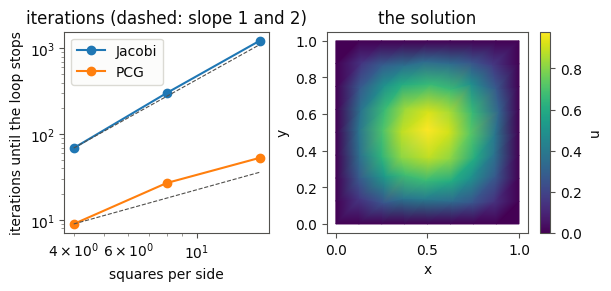
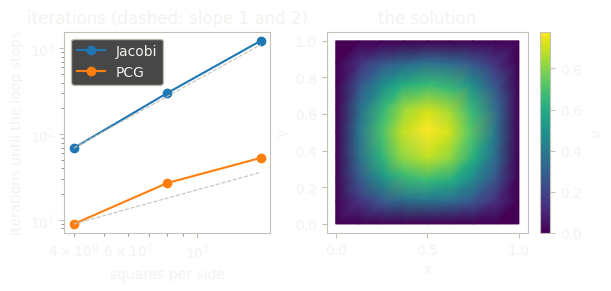

In [10]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from themed_figure import show

plot_style()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.0, 2.8), constrained_layout=True)
ax1.loglog(sides, jacobi_iterations, "o-", label="Jacobi")
ax1.loglog(sides, cg_iterations, "o-", label="PCG")
ax1.set_xlabel("squares per side")
ax1.set_ylabel("iterations until the loop stops")
s0 = np.array([sides[0], sides[-1]], dtype=float)
ax1.loglog(s0, cg_iterations[0] * (s0 / s0[0]), "--", color="#898781", lw=0.8)        # slope 1
ax1.loglog(s0, jacobi_iterations[0] * (s0 / s0[0]) ** 2, "--", color="#898781", lw=0.8)  # slope 2
ax1.set_title("iterations (dashed: slope 1 and 2)")
ax1.legend()
mesh = mtri.Triangulation(run["nodes"][:, 0], run["nodes"][:, 1], run["conn"])
shade = ax2.tripcolor(mesh, run["u"], shading="gouraud", cmap="viridis")
ax2.set_aspect("equal")
ax2.set_xlabel("x"); ax2.set_ylabel("y")
ax2.set_title("the solution")
fig.colorbar(shade, ax=ax2, label="u")
show()

## What just happened

- The stiffness matrix was never stored. A lane per (triangle, corner) applied it and `hawk.scatter` added the result
  into the nodes, the same pattern as the load.
- The solve was one graph with a device loop. Dot products went into one-element arrays and the next kernel read them
  with `.at(0)`; the residual was a reduction that wrote a one-cell flag, and the loop left when it reached zero. The
  iteration count came out of the run instead of going in.
- The answer matched a direct solve, and its error against the exact solution fell close to four times per halving of the
  mesh spacing, as a second-order scheme should.
- Jacobi needed far more iterations and the gap widens with the mesh; the graph, the flag and the three mesh kernels are the
  same for both.

## Next

- {doc}`22_heat_energy_check`, {doc}`23_fluids_pinned_frames`: host nodes and copies in a graph.
- {doc}`../graph_forms`: every form of the builder, including the capped device loop.